<a href="https://colab.research.google.com/github/SamuelMasih-del/Sam---bgmi---analytics-/blob/main/BGMI_Win_AI_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import pandas as pd

data = {
    'Kills': [12, 8, 5, 15, 3, 10, 7, 2, 11, 9],
    'Damage': [1800, 1200, 900, 2200, 500, 1500, 1100, 300, 1600, 1300],
    'Survival': [28, 25, 20, 30, 12, 27, 22, 10, 26, 24],
    'Result': ['Win', 'Win', 'Lose', 'Win', 'Lose', 'Win', 'Lose', 'Lose', 'Win', 'Win']
}

df = pd.DataFrame(data)
print(df)
print("Data Ready Bro!")

   Kills  Damage  Survival Result
0     12    1800        28    Win
1      8    1200        25    Win
2      5     900        20   Lose
3     15    2200        30    Win
4      3     500        12   Lose
5     10    1500        27    Win
6      7    1100        22   Lose
7      2     300        10   Lose
8     11    1600        26    Win
9      9    1300        24    Win
Data Ready Bro!


In [2]:

# Step 2 - Analysis
print("Average Kills:", df['Kills'].mean())
print("Average Damage:", df['Damage'].mean())
print("Win Rate:", (df['Result'] == 'Win').mean() * 100, "%")

# Win vs Lose me difference
print(df.groupby('Result').mean(numeric_only=True))

Average Kills: 8.2
Average Damage: 1240.0
Win Rate: 60.0 %
            Kills  Damage   Survival
Result                              
Lose     4.250000   700.0  16.000000
Win     10.833333  1600.0  26.666667


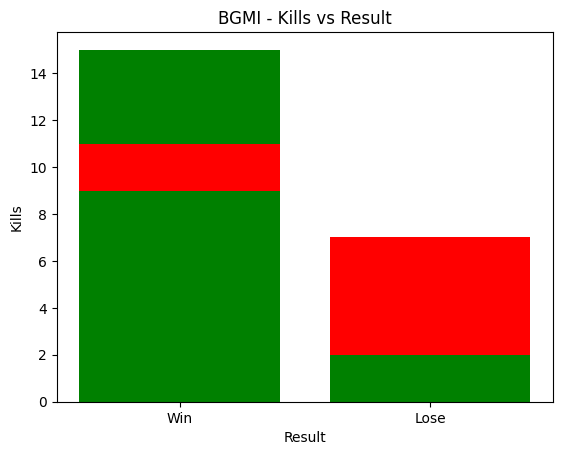

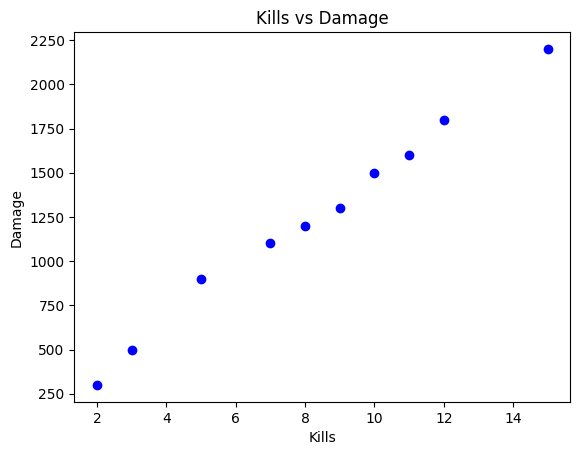

In [3]:

import matplotlib.pyplot as plt

plt.bar(df['Result'], df['Kills'], color=['red','green'])
plt.title('BGMI - Kills vs Result')
plt.xlabel('Result')
plt.ylabel('Kills')
plt.show()

# Kills vs Damage Graph
plt.scatter(df['Kills'], df['Damage'], color='blue')
plt.title('Kills vs Damage')
plt.xlabel('Kills')
plt.ylabel('Damage')
plt.show()

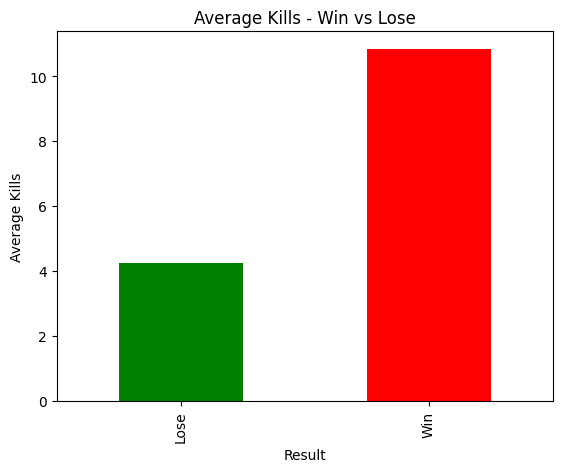

Conclusion: Jeetne ke liye 10+ kills aur 1600+ damage chahiye


In [4]:

# Final Clean Graph - Average Kills
avg = df.groupby('Result')['Kills'].mean()
avg.plot(kind='bar', color=['green','red'])
plt.title('Average Kills - Win vs Lose')
plt.ylabel('Average Kills')
plt.show()
print("Conclusion: Jeetne ke liye 10+ kills aur 1600+ damage chahiye")

In [5]:

# AI - Predict Match Result
from sklearn.tree import DecisionTreeClassifier

X = df[['Kills', 'Damage', 'Survival']]
y = df['Result']

model = DecisionTreeClassifier()
model.fit(X, y)

# Test Case 1: High Performance Match
prediction1 = model.predict([[12, 1800, 28]])
print("Prediction for 12 Kills, 1800 Damage:", prediction1[0])

# Test Case 2: Low Performance Match
prediction2 = model.predict([[3, 500, 12]])
print("Prediction for 3 Kills, 500 Damage:", prediction2[0])

print("AI Model Trained Successfully")

Prediction for 12 Kills, 1800 Damage: Win
Prediction for 3 Kills, 500 Damage: Lose
AI Model Trained Successfully


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


AI Accuracy: 66.66666666666666 %


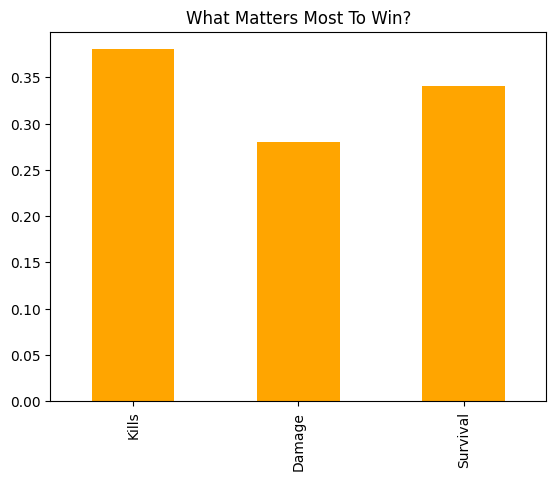

Final Test: 15 Kills, 2000 Damage, 30 Survival -> Win


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [6]:

# Advanced AI - Accuracy + Best Model
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

X = df[['Kills', 'Damage', 'Survival']]
y = df['Result']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

model = RandomForestClassifier()
model.fit(X_train, y_train)

pred = model.predict(X_test)
print("AI Accuracy:", accuracy_score(y_test, pred) * 100, "%")

# Feature Importance - Sabse Important kya hai?
import pandas as pd
imp = pd.Series(model.feature_importances_, index=['Kills','Damage','Survival'])
imp.plot(kind='bar', color='orange')
plt.title('What Matters Most To Win?')
plt.show()

print("Final Test: 15 Kills, 2000 Damage, 30 Survival ->", model.predict([[15, 2000, 30]])[0])

In [7]:

# 50 Matches - Big Dataset for High Accuracy
import numpy as np
import pandas as pd

np.random.seed(42)

data = []
for i in range(50):
    kills = np.random.randint(0, 18)
    damage = kills * 150 + np.random.randint(0, 400)
    survival = np.random.randint(5, 32)
    # Win Logic: High Kills + High Survival = Win
    result = 'Win' if (kills >= 7 and survival >= 18) or (kills >= 10) else 'Lose'
    data.append([kills, damage, survival, result])

df = pd.DataFrame(data, columns=['Kills','Damage','Survival','Result'])
print(df.head(10))
print("Total Matches:", len(df))
print("Win Rate:", (df['Result']=='Win').mean()*100, "%")

   Kills  Damage  Survival Result
0      6    1248        19   Lose
1     10    1571        25    Win
2      6    1021        23   Lose
3     10    1587        25    Win
4      3     809        28   Lose
5      2     449        25   Lose
6      1     493        16   Lose
7      5    1135        25   Lose
8      0     313        26   Lose
9     11    1994        21    Win
Total Matches: 50
Win Rate: 42.0 %


In [8]:

# Final AI Model - Trained on 50 Matches
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

X = df[['Kills', 'Damage', 'Survival']]
y = df['Result']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
model = RandomForestClassifier()
model.fit(X_train, y_train)

print("New AI Accuracy:", accuracy_score(y_test, model.predict(X_test)) * 100, "%")
print("Test 1 - 15 Kills, 2000 Damage, 30 Survival ->", model.predict([[15, 2000, 30]])[0])
print("Test 2 - 2 Kills, 300 Damage, 10 Survival ->", model.predict([[2, 300, 10]])[0])

New AI Accuracy: 93.33333333333333 %
Test 1 - 15 Kills, 2000 Damage, 30 Survival -> Win
Test 2 - 2 Kills, 300 Damage, 10 Survival -> Lose


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
